['firstName', 'age', 'bloodGroup', 'height', 'weight', 'eyeColor', 'role', 'university', 'birthDate']
Quantidade de usuários: 100
0    1996-05-30 00:00:00
1    1989-08-10 00:00:00
2    1982-11-06 00:00:00
3    1979-05-04 00:00:00
4    1994-06-13 00:00:00
Name: birthDate, dtype: object
            Quantidade  Porcentagem
bloodGroup                         
O-                  19         19.0
A+                  15         15.0
AB-                 13         13.0
AB+                 13         13.0
B+                  12         12.0
B-                  10         10.0
O+                  10         10.0
A-                   8          8.0


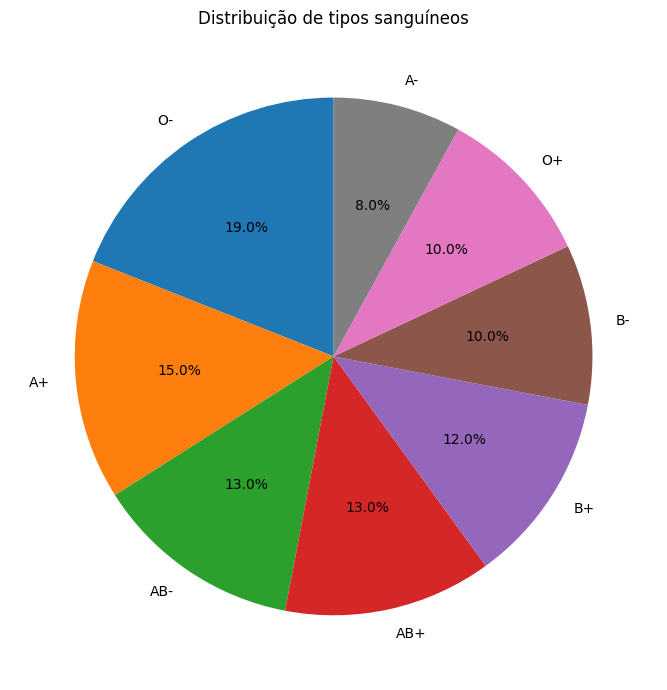

Pessoas abaixo de 30 anos: 34
Pessoas com 30 anos ou mais: 66


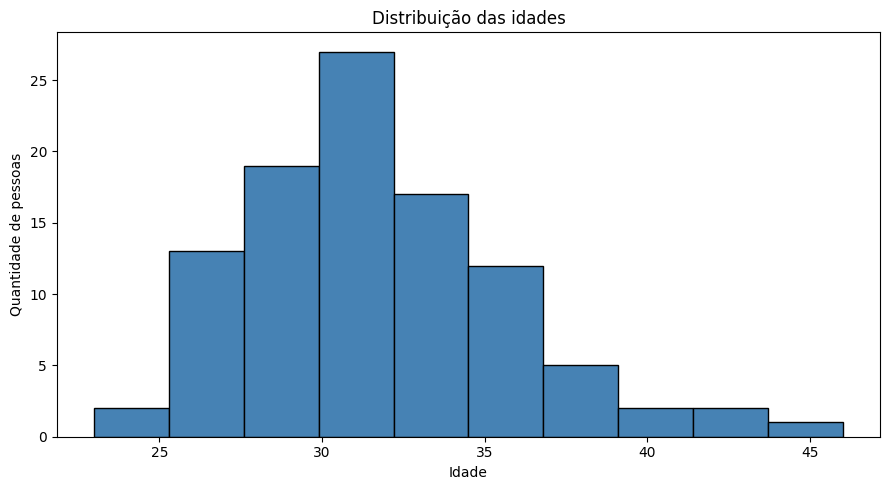

Cor mais comum: Brown (18)
Cor menos comum: Violet (7)
eyeColor
Brown     18
Hazel     16
Gray      14
Red       12
Blue      12
Green     11
Amber     10
Violet     7
Name: count, dtype: int64


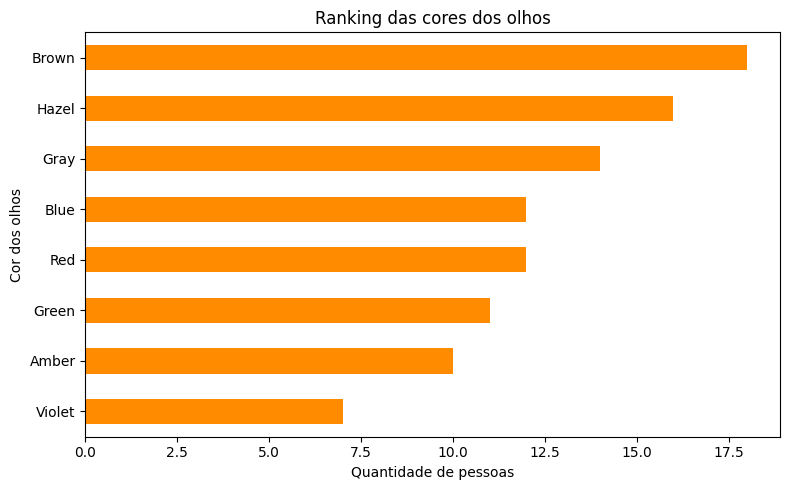

Correlação entre altura e peso: -0.12
Existe uma tendência positiva fraca: pessoas mais altas tendem a pesar um pouco mais, mas há bastante dispersão.


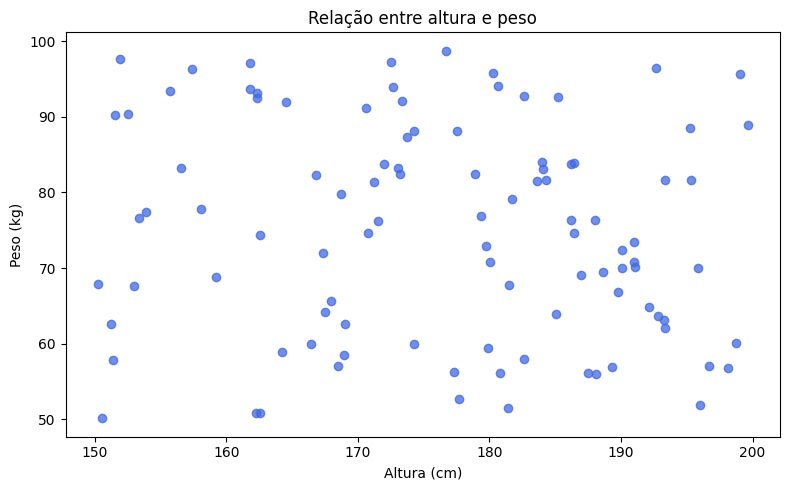

           Quantidade  Porcentagem
role                              
user               85         85.0
moderator          10         10.0
admin               5          5.0


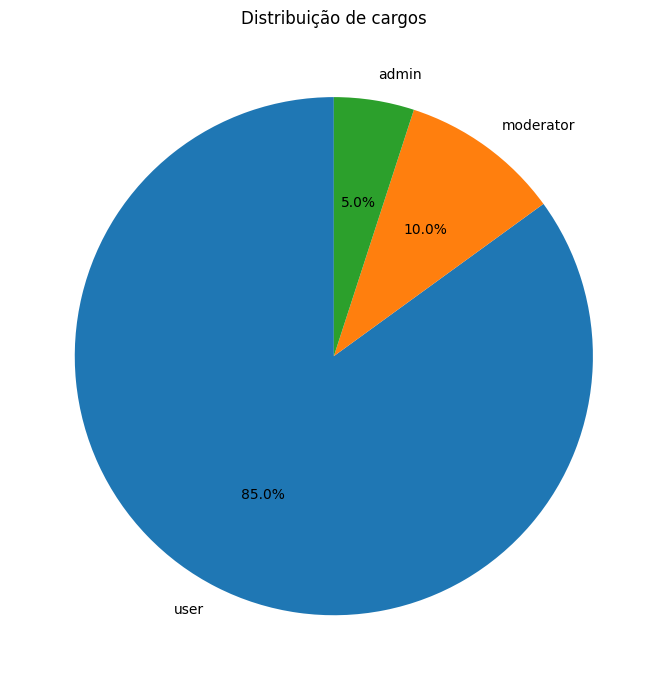

role
admin        188.66
user         176.35
moderator    170.59
Name: height, dtype: float64
Grupo mais alto, em média: admin


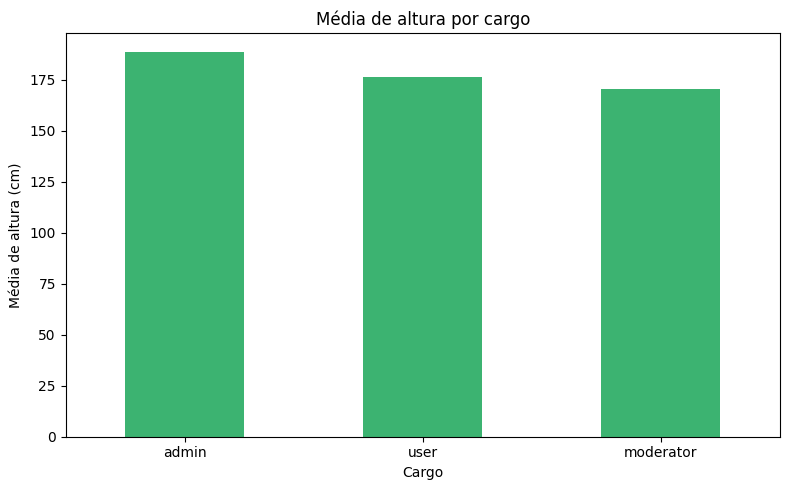

university
Northeastern University               5
Washington University in St. Louis    5
Ohio State University                 4
University of Pennsylvania            4
Harvard University                    4
Name: count, dtype: int64


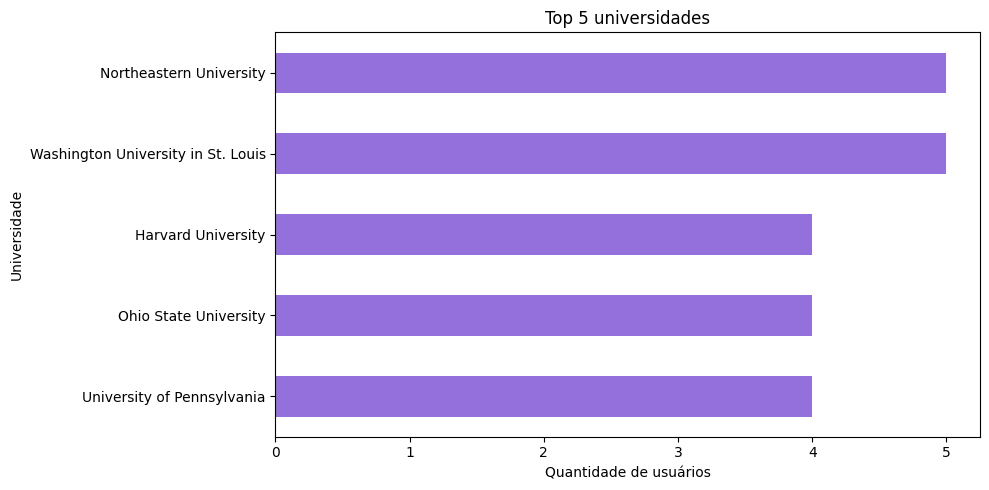

Menor peso: 50.10 kg
Maior peso: 98.77 kg
A maior concentração está aproximadamente entre 60 e 80 kg.


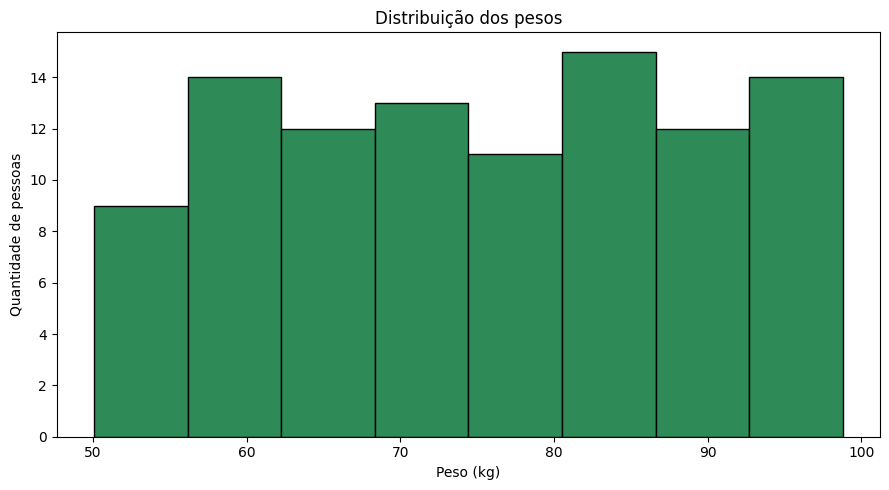

Atendem às duas condições: 4
Restante da base: 96


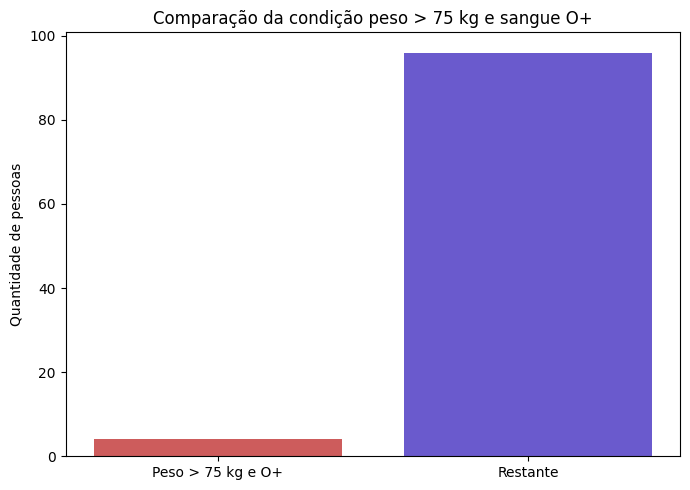

AttributeError: Can only use .dt accessor with datetimelike values

In [3]:
# %% [1] Importação e criação do DataFrame
import requests
import pandas as pd
import matplotlib.pyplot as plt

url = "https://dummyjson.com/users?limit=100"
resposta = requests.get(url, timeout=30)
resposta.raise_for_status()
dados_json = resposta.json()

# Cria o DataFrame com todos os dados
df_completo = pd.DataFrame(dados_json["users"])

# Seleciona as colunas usadas na atividade
colunas = [
    "firstName",
    "age",
    "bloodGroup",
    "height",
    "weight",
    "eyeColor",
    "role",
    "university",
    "birthDate",
]

df = df_completo[colunas].copy()

print(df.columns.to_list())
print(f"Quantidade de usuários: {len(df)}")


# %% [2] Tratamento da data de nascimento
# O .copy() acima evita o SettingWithCopyWarning.
df.loc[:, "birthDate"] = pd.to_datetime(
    df["birthDate"],
    format="%Y-%m-%d",
)

print(df["birthDate"].head())


# %% [3] Questão 1 - Distribuição de tipos sanguíneos
tipos_sanguineos = df["bloodGroup"].value_counts()
porcentagens_sanguineos = (tipos_sanguineos / len(df) * 100).round(2)

resultado_sanguineos = pd.DataFrame(
    {
        "Quantidade": tipos_sanguineos,
        "Porcentagem": porcentagens_sanguineos,
    }
)
print(resultado_sanguineos)

plt.figure(figsize=(7, 7))
plt.pie(
    tipos_sanguineos,
    labels=tipos_sanguineos.index,
    autopct="%1.1f%%",
    startangle=90,
)
plt.title("Distribuição de tipos sanguíneos")
plt.tight_layout()
plt.show()


# %% [4] Questão 2 - Distribuição de idades
jovens = (df["age"] < 30).sum()
maiores_ou_iguais = (df["age"] >= 30).sum()

print(f"Pessoas abaixo de 30 anos: {jovens}")
print(f"Pessoas com 30 anos ou mais: {maiores_ou_iguais}")

plt.figure(figsize=(9, 5))
plt.hist(df["age"], bins=10, edgecolor="black", color="steelblue")
plt.xlabel("Idade")
plt.ylabel("Quantidade de pessoas")
plt.title("Distribuição das idades")
plt.tight_layout()
plt.show()


# %% [5] Questão 3 - Cor dos olhos
cores_olhos = df["eyeColor"].value_counts()

print(f"Cor mais comum: {cores_olhos.index[0]} ({cores_olhos.iloc[0]})")
print(f"Cor menos comum: {cores_olhos.index[-1]} ({cores_olhos.iloc[-1]})")
print(cores_olhos)

plt.figure(figsize=(8, 5))
cores_olhos.sort_values().plot(kind="barh", color="darkorange")
plt.xlabel("Quantidade de pessoas")
plt.ylabel("Cor dos olhos")
plt.title("Ranking das cores dos olhos")
plt.tight_layout()
plt.show()


# %% [6] Questão 4 - Relação entre altura e peso
correlacao = df["height"].corr(df["weight"])
print(f"Correlação entre altura e peso: {correlacao:.2f}")
print(
    "Existe uma tendência positiva fraca: pessoas mais altas tendem "
    "a pesar um pouco mais, mas há bastante dispersão."
)

plt.figure(figsize=(8, 5))
plt.scatter(df["height"], df["weight"], alpha=0.75, color="royalblue")
plt.xlabel("Altura (cm)")
plt.ylabel("Peso (kg)")
plt.title("Relação entre altura e peso")
plt.tight_layout()
plt.show()


# %% [7] Questão 5 - Distribuição de cargos
cargos = df["role"].value_counts()
porcentagens_cargos = (cargos / len(df) * 100).round(2)

resultado_cargos = pd.DataFrame(
    {
        "Quantidade": cargos,
        "Porcentagem": porcentagens_cargos,
    }
)
print(resultado_cargos)

plt.figure(figsize=(7, 7))
plt.pie(
    cargos,
    labels=cargos.index,
    autopct="%1.1f%%",
    startangle=90,
)
plt.title("Distribuição de cargos")
plt.tight_layout()
plt.show()


# %% [8] Questão 6 - Média de altura por cargo
media_altura = df.groupby("role")["height"].mean().sort_values(ascending=False)

print(media_altura.round(2))
print(f"Grupo mais alto, em média: {media_altura.index[0]}")

plt.figure(figsize=(8, 5))
media_altura.plot(kind="bar", color="mediumseagreen")
plt.xlabel("Cargo")
plt.ylabel("Média de altura (cm)")
plt.title("Média de altura por cargo")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# %% [9] Questão 7 - Top 5 universidades
top5_universidades = df["university"].value_counts().head(5)
print(top5_universidades)

plt.figure(figsize=(10, 5))
top5_universidades.sort_values().plot(kind="barh", color="mediumpurple")
plt.xlabel("Quantidade de usuários")
plt.ylabel("Universidade")
plt.title("Top 5 universidades")
plt.tight_layout()
plt.show()


# %% [10] Questão 8 - Concentração de peso
print(f"Menor peso: {df['weight'].min():.2f} kg")
print(f"Maior peso: {df['weight'].max():.2f} kg")
print("A maior concentração está aproximadamente entre 60 e 80 kg.")

plt.figure(figsize=(9, 5))
plt.hist(df["weight"], bins=8, edgecolor="black", color="seagreen")
plt.xlabel("Peso (kg)")
plt.ylabel("Quantidade de pessoas")
plt.title("Distribuição dos pesos")
plt.tight_layout()
plt.show()


# %% [11] Questão 9 - Peso acima de 75 kg e tipo sanguíneo O+
condicao = (df["weight"] > 75) & (df["bloodGroup"] == "O+")
quantidade_condicao = condicao.sum()
restante = len(df) - quantidade_condicao

print(f"Atendem às duas condições: {quantidade_condicao}")
print(f"Restante da base: {restante}")

plt.figure(figsize=(7, 5))
plt.bar(
    ["Peso > 75 kg e O+", "Restante"],
    [quantidade_condicao, restante],
    color=["indianred", "slateblue"],
)
plt.ylabel("Quantidade de pessoas")
plt.title("Comparação da condição peso > 75 kg e sangue O+")
plt.tight_layout()
plt.show()


# %% [12] Questão 10 - Sazonalidade de nascimentos
nomes_meses = [
    "Janeiro",
    "Fevereiro",
    "Março",
    "Abril",
    "Maio",
    "Junho",
    "Julho",
    "Agosto",
    "Setembro",
    "Outubro",
    "Novembro",
    "Dezembro",
]

nascimentos = df["birthDate"].dt.month.value_counts().sort_index()
nascimentos.index = [nomes_meses[mes - 1] for mes in nascimentos.index]

print(nascimentos)
print(
    f"Mês com mais aniversariantes: {nascimentos.idxmax()} "
    f"({nascimentos.max()} pessoas)"
)

plt.figure(figsize=(11, 5))
nascimentos.plot(kind="bar", color="coral")
plt.xlabel("Mês")
plt.ylabel("Quantidade de aniversariantes")
plt.title("Nascimentos por mês")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [18]:
# %% [2] Tratamento da data de nascimento

df["birthDate"] = pd.to_datetime(
    df["birthDate"],
    format="%Y-%m-%d"
)

print(df["birthDate"].head())
print(df["birthDate"].dtype)

0   1996-05-30
1   1989-08-10
2   1982-11-06
3   1979-05-04
4   1994-06-13
Name: birthDate, dtype: datetime64[ns]
datetime64[ns]


            Quantidade  Porcentagem
bloodGroup                         
O-                  19         19.0
A+                  15         15.0
AB-                 13         13.0
AB+                 13         13.0
B+                  12         12.0
B-                  10         10.0
O+                  10         10.0
A-                   8          8.0


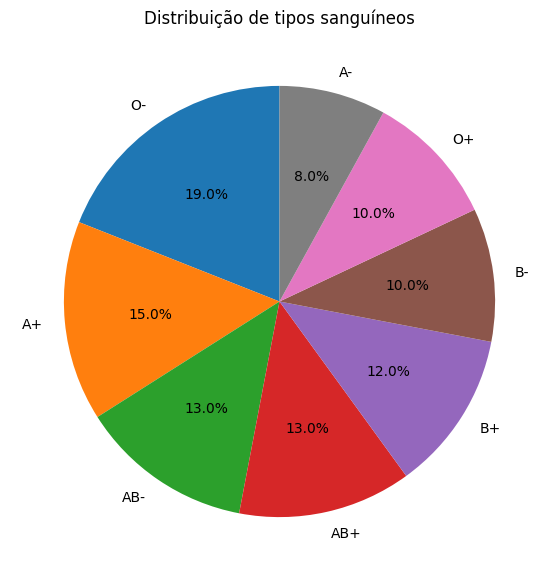

In [8]:
# QUESTÃO 1 - DISTRIBUIÇÃO DE TIPOS SANGUÍNEOS

tipos_sanguineos = df["bloodGroup"].value_counts()

porcentagens_sanguineos = (
    tipos_sanguineos / len(df) * 100
).round(2)

resultado_sanguineos = pd.DataFrame({
    "Quantidade": tipos_sanguineos,
    "Porcentagem": porcentagens_sanguineos
})

print(resultado_sanguineos)

plt.figure(figsize=(7, 7))

plt.pie(
    tipos_sanguineos,
    labels=tipos_sanguineos.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribuição de tipos sanguíneos")
plt.show()

Pessoas abaixo de 30 anos: 34
Pessoas com 30 anos ou mais: 66


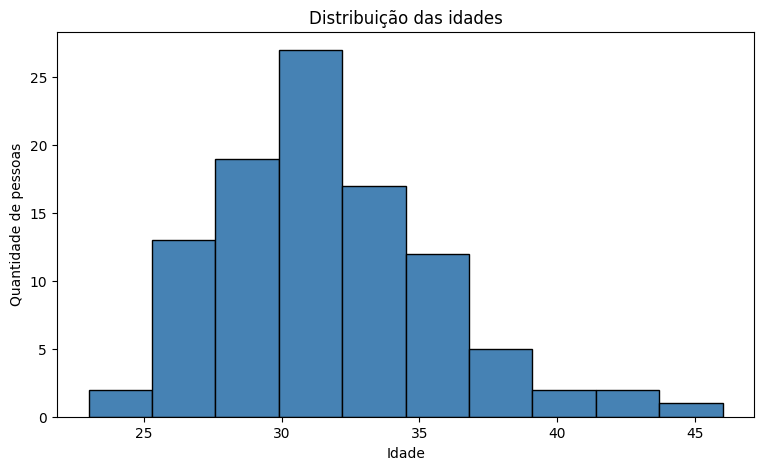

In [9]:
# QUESTÃO 2 - DISTRIBUIÇÃO DE IDADES

jovens = (df["age"] < 30).sum()
maiores_ou_iguais = (df["age"] >= 30).sum()

print(f"Pessoas abaixo de 30 anos: {jovens}")
print(f"Pessoas com 30 anos ou mais: {maiores_ou_iguais}")

plt.figure(figsize=(9, 5))

plt.hist(
    df["age"],
    bins=10,
    edgecolor="black",
    color="steelblue"
)

plt.xlabel("Idade")
plt.ylabel("Quantidade de pessoas")
plt.title("Distribuição das idades")
plt.show()

Cor mais comum: Brown (18)
Cor menos comum: Violet (7)

Quantidade por cor:
eyeColor
Brown     18
Hazel     16
Gray      14
Red       12
Blue      12
Green     11
Amber     10
Violet     7
Name: count, dtype: int64


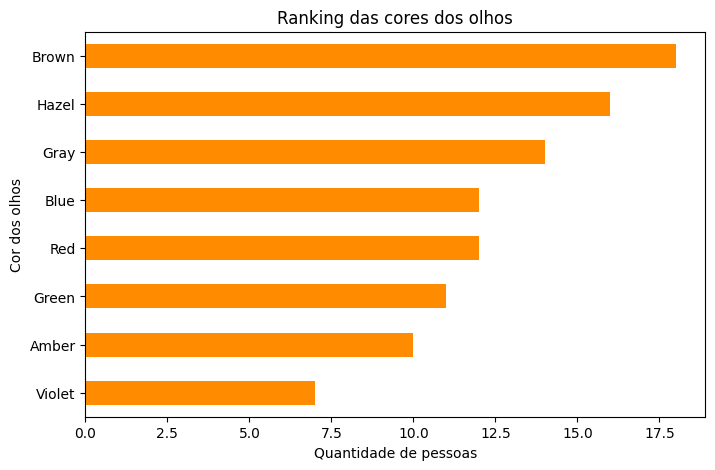

In [10]:
# QUESTÃO 3 - COR DOS OLHOS

cores_olhos = df["eyeColor"].value_counts()

print(f"Cor mais comum: {cores_olhos.index[0]} ({cores_olhos.iloc[0]})")
print(f"Cor menos comum: {cores_olhos.index[-1]} ({cores_olhos.iloc[-1]})")

print("\nQuantidade por cor:")
print(cores_olhos)

plt.figure(figsize=(8, 5))

cores_olhos.sort_values().plot(
    kind="barh",
    color="darkorange"
)

plt.xlabel("Quantidade de pessoas")
plt.ylabel("Cor dos olhos")
plt.title("Ranking das cores dos olhos")
plt.show()

Correlação entre altura e peso: -0.12
Existe uma tendência positiva fraca: pessoas mais altas tendem a pesar um pouco mais, mas há bastante dispersão.


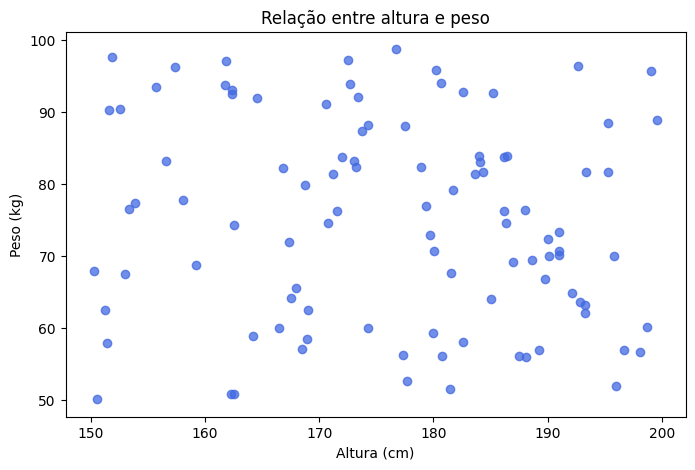

In [11]:
# QUESTÃO 4 - RELAÇÃO ENTRE ALTURA E PESO

correlacao = df["height"].corr(df["weight"])

print(f"Correlação entre altura e peso: {correlacao:.2f}")

print(
    "Existe uma tendência positiva fraca: pessoas mais altas tendem "
    "a pesar um pouco mais, mas há bastante dispersão."
)

plt.figure(figsize=(8, 5))

plt.scatter(
    df["height"],
    df["weight"],
    alpha=0.75,
    color="royalblue"
)

plt.xlabel("Altura (cm)")
plt.ylabel("Peso (kg)")
plt.title("Relação entre altura e peso")
plt.show()

           Quantidade  Porcentagem
role                              
user               85         85.0
moderator          10         10.0
admin               5          5.0


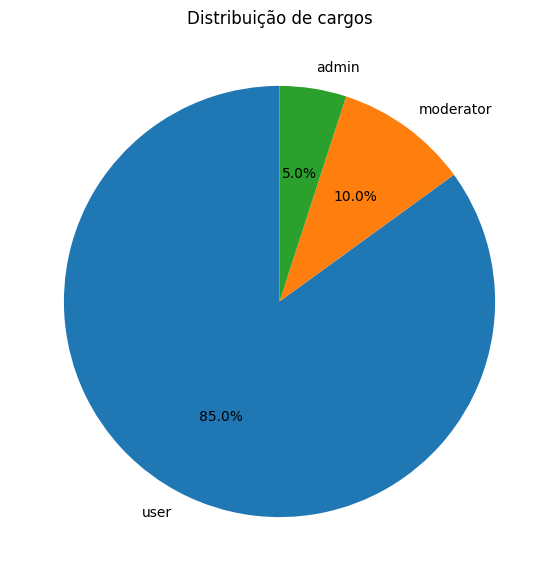

In [12]:
# QUESTÃO 5 - DISTRIBUIÇÃO DE CARGOS

cargos = df["role"].value_counts()

porcentagens_cargos = (
    cargos / len(df) * 100
).round(2)

resultado_cargos = pd.DataFrame({
    "Quantidade": cargos,
    "Porcentagem": porcentagens_cargos
})

print(resultado_cargos)

plt.figure(figsize=(7, 7))

plt.pie(
    cargos,
    labels=cargos.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribuição de cargos")
plt.show()

Média de altura por cargo:
role
admin        188.66
user         176.35
moderator    170.59
Name: height, dtype: float64

Grupo mais alto, em média: admin


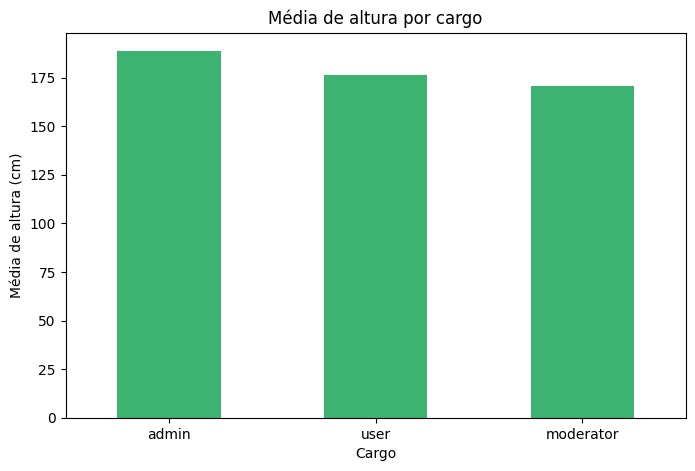

In [13]:
# QUESTÃO 6 - MÉDIA DE ALTURA POR CARGO

media_altura = (
    df.groupby("role")["height"]
    .mean()
    .sort_values(ascending=False)
)

print("Média de altura por cargo:")
print(media_altura.round(2))

print(
    f"\nGrupo mais alto, em média: {media_altura.index[0]}"
)

plt.figure(figsize=(8, 5))

media_altura.plot(
    kind="bar",
    color="mediumseagreen"
)

plt.xlabel("Cargo")
plt.ylabel("Média de altura (cm)")
plt.title("Média de altura por cargo")
plt.xticks(rotation=0)
plt.show()

Top 5 universidades:
university
Northeastern University               5
Washington University in St. Louis    5
Ohio State University                 4
University of Pennsylvania            4
Harvard University                    4
Name: count, dtype: int64


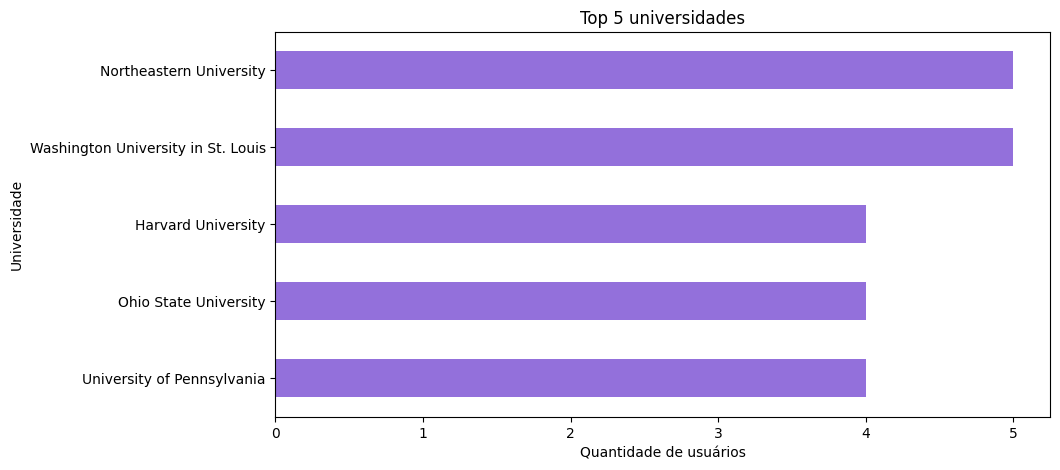

In [14]:
# QUESTÃO 7 - TOP 5 UNIVERSIDADES

top5_universidades = (
    df["university"]
    .value_counts()
    .head(5)
)

print("Top 5 universidades:")
print(top5_universidades)

plt.figure(figsize=(10, 5))

top5_universidades.sort_values().plot(
    kind="barh",
    color="mediumpurple"
)

plt.xlabel("Quantidade de usuários")
plt.ylabel("Universidade")
plt.title("Top 5 universidades")
plt.show()

Menor peso: 50.10 kg
Maior peso: 98.77 kg
A maior concentração de pessoas está aproximadamente entre 60 e 80 kg.


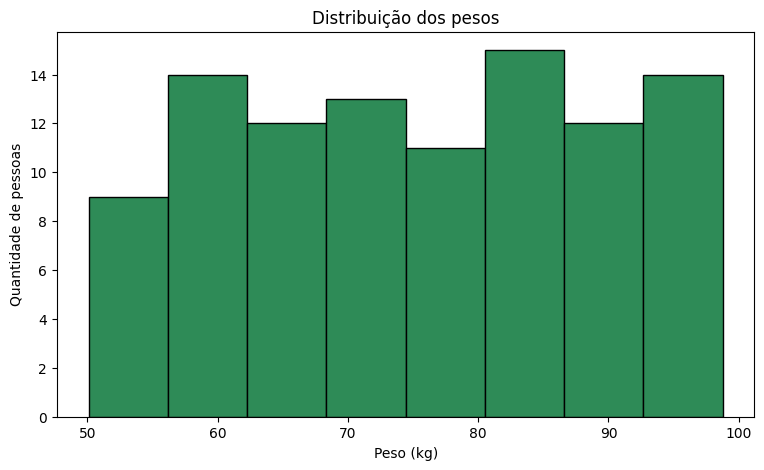

In [15]:
# QUESTÃO 8 - CONCENTRAÇÃO DE PESO

print(f"Menor peso: {df['weight'].min():.2f} kg")
print(f"Maior peso: {df['weight'].max():.2f} kg")

print(
    "A maior concentração de pessoas está aproximadamente "
    "entre 60 e 80 kg."
)

plt.figure(figsize=(9, 5))

plt.hist(
    df["weight"],
    bins=8,
    edgecolor="black",
    color="seagreen"
)

plt.xlabel("Peso (kg)")
plt.ylabel("Quantidade de pessoas")
plt.title("Distribuição dos pesos")
plt.show()

Pessoas com mais de 75 kg e sangue O+: 4
Restante da base: 96


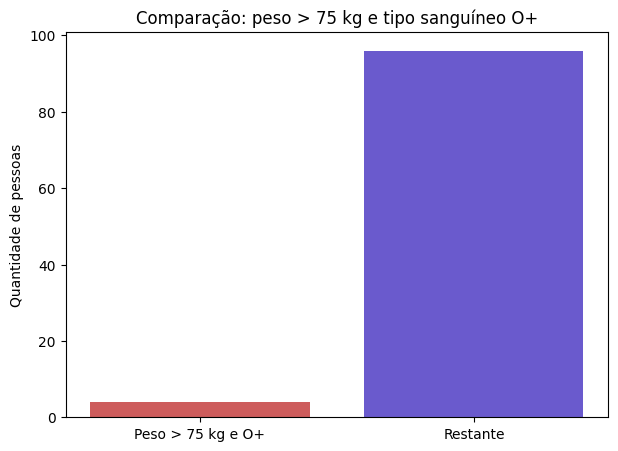

In [16]:
# QUESTÃO 9 - PESO ACIMA DE 75 KG E TIPO SANGUÍNEO O+

condicao = (
    (df["weight"] > 75)
    & (df["bloodGroup"] == "O+")
)

quantidade_condicao = condicao.sum()
restante = len(df) - quantidade_condicao

print(
    f"Pessoas com mais de 75 kg e sangue O+: "
    f"{quantidade_condicao}"
)

print(f"Restante da base: {restante}")

plt.figure(figsize=(7, 5))

plt.bar(
    ["Peso > 75 kg e O+", "Restante"],
    [quantidade_condicao, restante],
    color=["indianred", "slateblue"]
)

plt.ylabel("Quantidade de pessoas")
plt.title("Comparação: peso > 75 kg e tipo sanguíneo O+")
plt.show()

Quantidade de nascimentos por mês:
Janeiro       4
Fevereiro     9
Março        10
Abril         9
Maio          7
Junho        14
Julho         5
Agosto        8
Setembro     11
Outubro       8
Novembro      8
Dezembro      7
Name: count, dtype: int64

Mês com mais aniversariantes: Junho (14 pessoas)


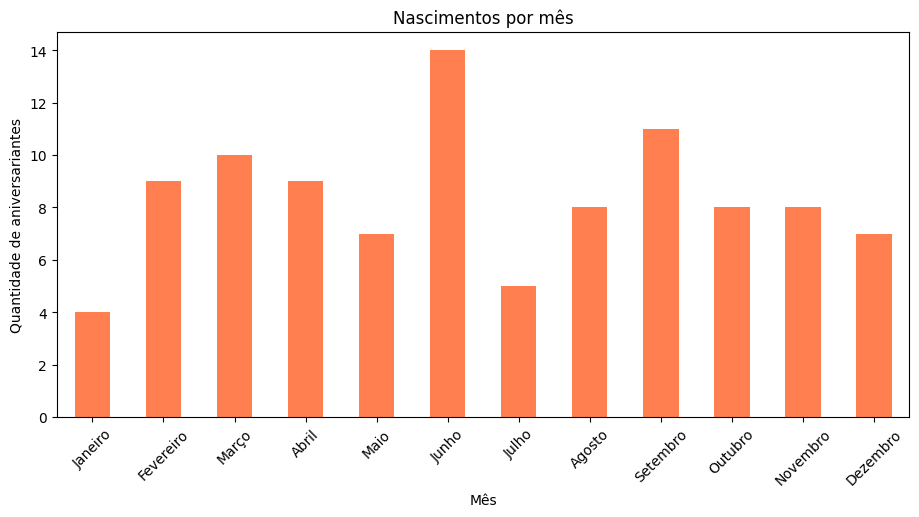

In [19]:
# QUESTÃO 10 - SAZONALIDADE DE NASCIMENTOS

nomes_meses = [
    "Janeiro",
    "Fevereiro",
    "Março",
    "Abril",
    "Maio",
    "Junho",
    "Julho",
    "Agosto",
    "Setembro",
    "Outubro",
    "Novembro",
    "Dezembro"
]

nascimentos = (
    df["birthDate"]
    .dt.month
    .value_counts()
    .sort_index()
)

nascimentos.index = [
    nomes_meses[mes - 1]
    for mes in nascimentos.index
]

print("Quantidade de nascimentos por mês:")
print(nascimentos)

print(
    f"\nMês com mais aniversariantes: "
    f"{nascimentos.idxmax()} "
    f"({nascimentos.max()} pessoas)"
)

plt.figure(figsize=(11, 5))

nascimentos.plot(
    kind="bar",
    color="coral"
)

plt.xlabel("Mês")
plt.ylabel("Quantidade de aniversariantes")
plt.title("Nascimentos por mês")
plt.xticks(rotation=45)
plt.show()